In [1]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm import tqdm

In [2]:
DATASET_PATH = Path("../datasets/PlantVillage")

print(DATASET_PATH.exists())

True


In [3]:
classes = sorted([folder.name for folder in DATASET_PATH.iterdir() if folder.is_dir()])

print(f"Total Classes: {len(classes)}")
print()

for cls in classes:
    print(cls)

Total Classes: 2

train
val


In [4]:
image_counts = {}

total_images = 0

for cls in classes:
    count = len(list((DATASET_PATH / cls).glob("*")))
    image_counts[cls] = count
    total_images += count

print(f"Total Images: {total_images}")

Total Images: 76


In [5]:
df = pd.DataFrame(
    image_counts.items(),
    columns=["Class", "Images"]
)

df = df.sort_values("Images", ascending=False)

df.head()

,Class,Images
0,train,38
1,val,38


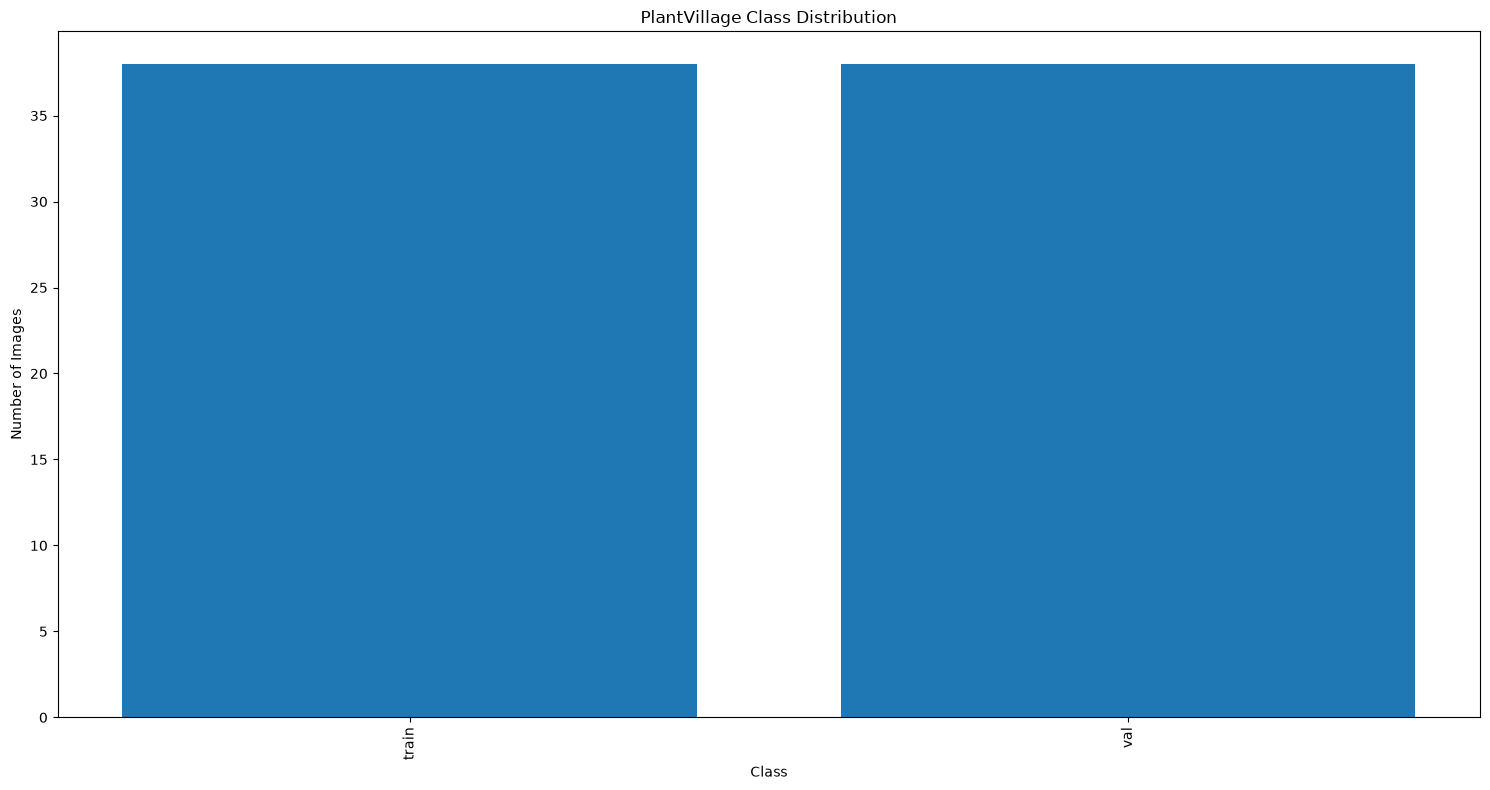

In [6]:
plt.figure(figsize=(15,8))

plt.bar(df["Class"], df["Images"])

plt.xticks(rotation=90)

plt.xlabel("Class")

plt.ylabel("Number of Images")

plt.title("PlantVillage Class Distribution")

plt.tight_layout()

plt.show()

ValueError: Sample larger than population or is negative

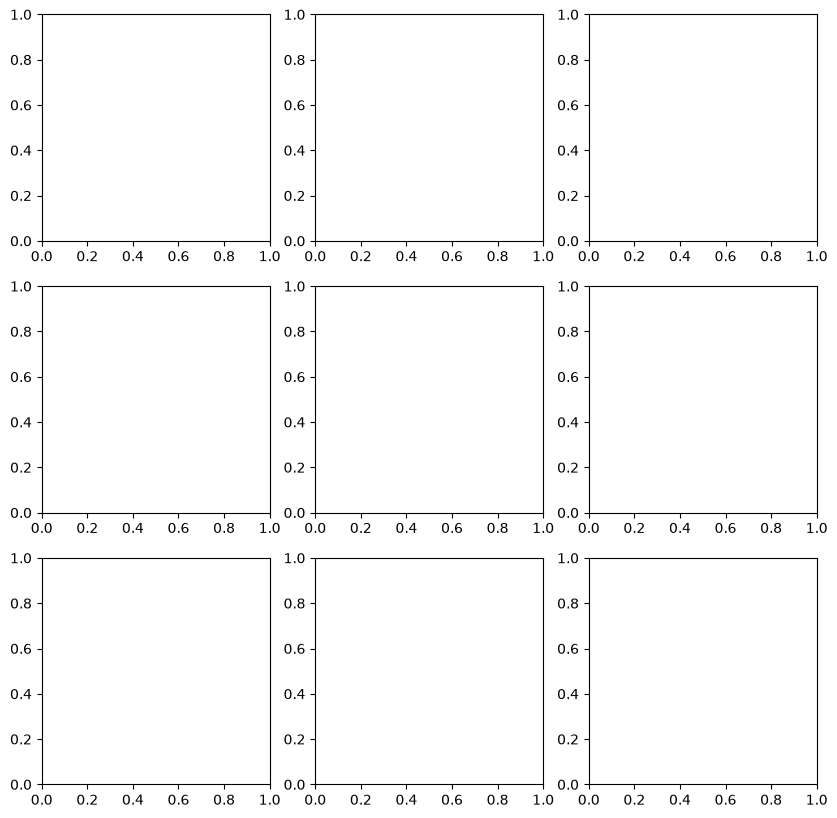

In [7]:
import random

fig, axes = plt.subplots(3, 3, figsize=(10,10))

sample_classes = random.sample(classes, 9)

for ax, cls in zip(axes.flat, sample_classes):

    image_path = random.choice(list((DATASET_PATH / cls).glob("*")))

    img = Image.open(image_path)

    ax.imshow(img)

    ax.set_title(cls, fontsize=8)

    ax.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
widths = []
heights = []

for cls in tqdm(classes):

    for image_path in (DATASET_PATH / cls).glob("*"):

        img = Image.open(image_path)

        widths.append(img.width)

        heights.append(img.height)

 80%|████████  | 12/15 [00:03<00:00,  3.12it/s]


UnidentifiedImageError: cannot identify image file '../datasets/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c'

In [ ]:
print(f"Minimum Width : {min(widths)}")
print(f"Maximum Width : {max(widths)}")
print(f"Average Width : {sum(widths)/len(widths):.2f}")

print()

print(f"Minimum Height : {min(heights)}")
print(f"Maximum Height : {max(heights)}")
print(f"Average Height : {sum(heights)/len(heights):.2f}")

Minimum Width : 256
Maximum Width : 256
Average Width : 256.00

Minimum Height : 256
Maximum Height : 256
Average Height : 256.00


In [ ]:
corrupt_images = []

for cls in tqdm(classes):

    for image_path in (DATASET_PATH / cls).glob("*"):

        try:
            img = Image.open(image_path)
            img.verify()

        except Exception:

            corrupt_images.append(image_path)

print(f"Corrupt Images: {len(corrupt_images)}")
print(corrupt_images)


100%|██████████| 15/15 [00:00<00:00, 33.57it/s]

Corrupt Images: 0
[]


In [ ]:
import os

os.remove(corrupt_images[0])

In [ ]:
print("=" * 40)
print("DATASET SUMMARY")
print("=" * 40)

print(f"Total Classes : {len(classes)}")
print(f"Total Images  : {total_images}")
print(f"Corrupt Images: {len(corrupt_images)}")
print(f"Average Width : {sum(widths)/len(widths):.2f}")
print(f"Average Height: {sum(heights)/len(heights):.2f}")

DATASET SUMMARY
Total Classes : 15
Total Images  : 20639
Corrupt Images: 1
Average Width : 256.00
Average Height: 256.00
